In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

# Show image helper (works with gray or BGR)
def show_image(img, title="", cmap="gray"):
    plt.figure(figsize=(5,5))
    if len(img.shape) == 3 and img.shape[2] == 3:
        # BGR → RGB for OpenCV images
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        plt.imshow(img_rgb)
        cmap = None
    else:
        plt.imshow(img, cmap=cmap)
    plt.title(title)
    plt.axis("off")
    plt.show()


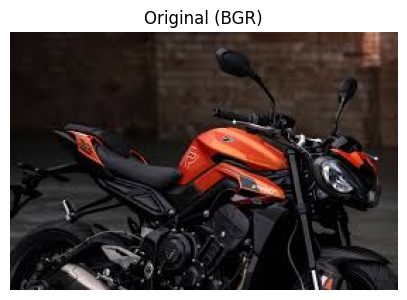

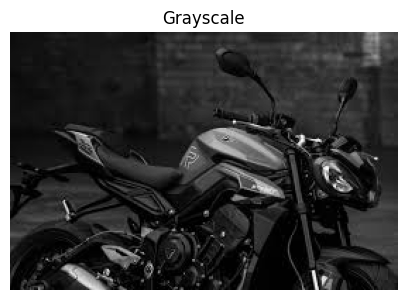

In [3]:
# Try to load a real image, else create synthetic
image_path = "input.jpeg"  

img = cv2.imread(image_path)

if img is None:
    print("Image not found, creating a synthetic test image...")
    h, w = 512, 512
    img = np.zeros((h, w, 3), dtype=np.uint8)
    cv2.rectangle(img, (50, 50), (200, 200), (255, 255, 255), -1)
    cv2.circle(img, (350, 350), 80, (255, 255, 255), -1)
    cv2.line(img, (0, 0), (511, 511), (255, 255, 255), 5)

gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

show_image(img, "Original (BGR)")
show_image(gray, "Grayscale")


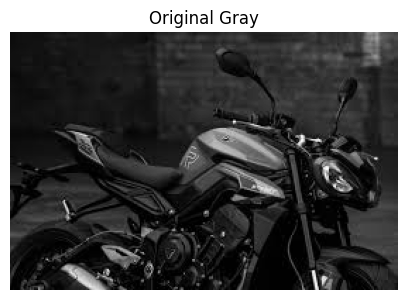

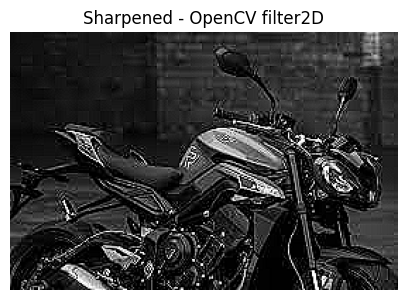

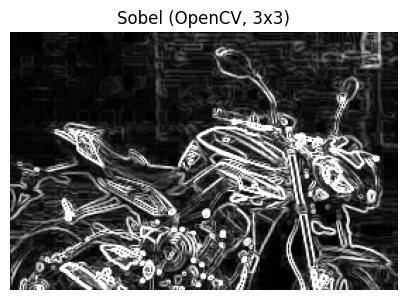

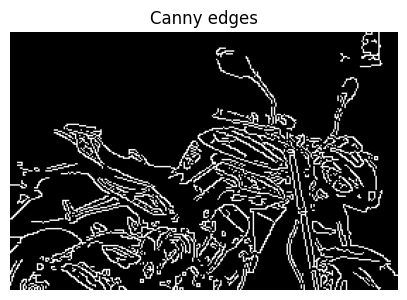

Saved before/after images.


In [4]:
# 1) Simple sharpening kernel with filter2D
sharpen_kernel = np.array([[0, -1,  0],
                           [-1, 5, -1],
                           [0, -1,  0]], dtype=np.float32)

sharp_opencv = cv2.filter2D(gray, ddepth=-1, kernel=sharpen_kernel)

# 2) OpenCV Sobel (3×3)
sobelx_cv = cv2.Sobel(gray, cv2.CV_64F, 1, 0, ksize=3)
sobely_cv = cv2.Sobel(gray, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag_cv = cv2.magnitude(sobelx_cv, sobely_cv)
sobel_mag_cv = cv2.convertScaleAbs(sobel_mag_cv)

# 3) Canny edge detector
canny = cv2.Canny(gray, threshold1=100, threshold2=200)

# Show before / after
show_image(gray, "Original Gray")
show_image(sharp_opencv, "Sharpened - OpenCV filter2D")
show_image(sobel_mag_cv, "Sobel (OpenCV, 3x3)")
show_image(canny, "Canny edges")

# Save before/after (for deliverables)
cv2.imwrite("before_gray.png", gray)
cv2.imwrite("after_sharpen_opencv.png", sharp_opencv)
cv2.imwrite("after_sobel_cv_3x3.png", sobel_mag_cv)
cv2.imwrite("after_canny.png", canny)
print("Saved before/after images.")


In [5]:
def convolve2d_naive(image, kernel, padding="same"):
    """
    image: 2D np.array (grayscale)
    kernel: 2D np.array
    padding: "same" or "valid"
    """
    img = image.astype(np.float32)
    ker = np.flipud(np.fliplr(kernel.astype(np.float32)))  # flip kernel for convolution

    H, W = img.shape
    kH, kW = ker.shape

    if padding == "same":
        pad_h = kH // 2
        pad_w = kW // 2
        img_padded = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")
    else:
        img_padded = img
        pad_h = pad_w = 0

    H_p, W_p = img_padded.shape
    out_h = H_p - kH + 1
    out_w = W_p - kW + 1

    output = np.zeros((out_h, out_w), dtype=np.float32)

    # Double loop – slow but simple
    for i in range(out_h):
        for j in range(out_w):
            region = img_padded[i:i+kH, j:j+kW]
            output[i, j] = np.sum(region * ker)

    if padding == "same":
        return output
    else:
        return output[:H-kH+1, :W-kW+1]


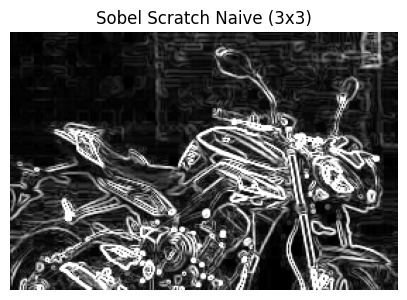

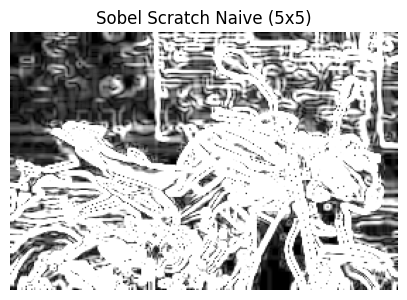

In [6]:
# Sobel kernels 3x3
sobel3x3_x = np.array([[-1, 0, 1],
                       [-2, 0, 2],
                       [-1, 0, 1]], dtype=np.float32)

sobel3x3_y = np.array([[-1, -2, -1],
                       [ 0,  0,  0],
                       [ 1,  2,  1]], dtype=np.float32)

# Sobel-like 5x5 kernels (one common version)
sobel5x5_x = np.array([
    [-2, -1, 0, 1, 2],
    [-3, -2, 0, 2, 3],
    [-4, -3, 0, 3, 4],
    [-3, -2, 0, 2, 3],
    [-2, -1, 0, 1, 2]
], dtype=np.float32)

sobel5x5_y = sobel5x5_x.T

def sobel_scratch_naive(image, ksize=3):
    if ksize == 3:
        kx, ky = sobel3x3_x, sobel3x3_y
    elif ksize == 5:
        kx, ky = sobel5x5_x, sobel5x5_y
    else:
        raise ValueError("ksize must be 3 or 5.")

    gx = convolve2d_naive(image, kx, padding="same")
    gy = convolve2d_naive(image, ky, padding="same")
    mag = np.sqrt(gx**2 + gy**2)
    mag = np.clip(mag, 0, 255).astype(np.uint8)
    return mag

sobel_naive_3 = sobel_scratch_naive(gray, ksize=3)
sobel_naive_5 = sobel_scratch_naive(gray, ksize=5)

show_image(sobel_naive_3, "Sobel Scratch Naive (3x3)")
show_image(sobel_naive_5, "Sobel Scratch Naive (5x5)")


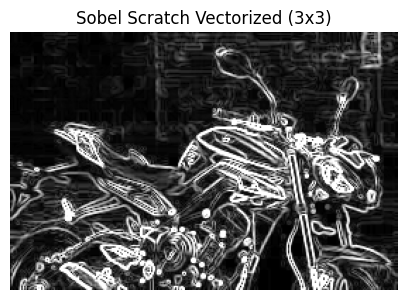

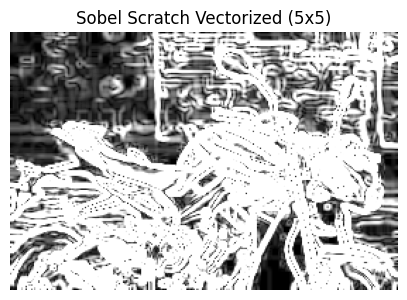

In [7]:
from numpy.lib.stride_tricks import as_strided

def im2col_sliding_strided(image, kH, kW):
    """
    Convert image into sliding blocks (patches) using stride tricks.
    Returns an array of shape (out_h * out_w, kH * kW)
    """
    H, W = image.shape
    out_h = H - kH + 1
    out_w = W - kW + 1

    shape = (out_h, out_w, kH, kW)
    strides = (image.strides[0], image.strides[1], image.strides[0], image.strides[1])

    patches = as_strided(image, shape=shape, strides=strides)
    return patches.reshape(-1, kH * kW), out_h, out_w

def convolve2d_vectorized(image, kernel, padding="same"):
    img = image.astype(np.float32)
    ker = np.flipud(np.fliplr(kernel.astype(np.float32)))
    kH, kW = ker.shape

    if padding == "same":
        pad_h = kH // 2
        pad_w = kW // 2
        img = np.pad(img, ((pad_h, pad_h), (pad_w, pad_w)), mode="reflect")

    patches, out_h, out_w = im2col_sliding_strided(img, kH, kW)
    ker_flat = ker.flatten().reshape(-1, 1)

    out_flat = patches @ ker_flat   # (N, kH*kW) @ (kH*kW, 1) -> (N, 1)
    output = out_flat.reshape(out_h, out_w)
    return output

def sobel_scratch_vectorized(image, ksize=3):
    if ksize == 3:
        kx, ky = sobel3x3_x, sobel3x3_y
    elif ksize == 5:
        kx, ky = sobel5x5_x, sobel5x5_y
    else:
        raise ValueError("ksize must be 3 or 5.")

    gx = convolve2d_vectorized(image, kx, padding="same")
    gy = convolve2d_vectorized(image, ky, padding="same")
    mag = np.sqrt(gx**2 + gy**2)
    mag = np.clip(mag, 0, 255).astype(np.uint8)
    return mag

sobel_vec_3 = sobel_scratch_vectorized(gray, ksize=3)
sobel_vec_5 = sobel_scratch_vectorized(gray, ksize=5)

show_image(sobel_vec_3, "Sobel Scratch Vectorized (3x3)")
show_image(sobel_vec_5, "Sobel Scratch Vectorized (5x5)")


In [8]:
def time_function(func, *args, repeats=5, **kwargs):
    """
    Run a function multiple times and return the best (min) time.
    """
    times = []
    for _ in range(repeats):
        start = time.perf_counter()
        _ = func(*args, **kwargs)
        end = time.perf_counter()
        times.append(end - start)
    return min(times)


In [9]:
# OpenCV Sobel wrappers for fair comparison
def sobel_cv_3(image):
    sx = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
    sy = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)
    mag = cv2.magnitude(sx, sy)
    return mag

def sobel_cv_5(image):
    sx = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=5)
    sy = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=5)
    mag = cv2.magnitude(sx, sy)
    return mag

# Time everything
t_cv_3   = time_function(sobel_cv_3, gray)
t_naive_3 = time_function(sobel_scratch_naive, gray, ksize=3)
t_vec_3   = time_function(sobel_scratch_vectorized, gray, ksize=3)

t_cv_5   = time_function(sobel_cv_5, gray)
t_naive_5 = time_function(sobel_scratch_naive, gray, ksize=5)
t_vec_5   = time_function(sobel_scratch_vectorized, gray, ksize=5)

labels = [
    "cv2 Sobel 3x3",
    "Naive Sobel 3x3",
    "Vectorized Sobel 3x3",
    "cv2 Sobel 5x5",
    "Naive Sobel 5x5",
    "Vectorized Sobel 5x5"
]

times = [t_cv_3, t_naive_3, t_vec_3, t_cv_5, t_naive_5, t_vec_5]

for l, t in zip(labels, times):
    print(f"{l}: {t*1000:.3f} ms")


cv2 Sobel 3x3: 0.504 ms
Naive Sobel 3x3: 145.363 ms
Vectorized Sobel 3x3: 1.332 ms
cv2 Sobel 5x5: 0.159 ms
Naive Sobel 5x5: 149.371 ms
Vectorized Sobel 5x5: 2.446 ms


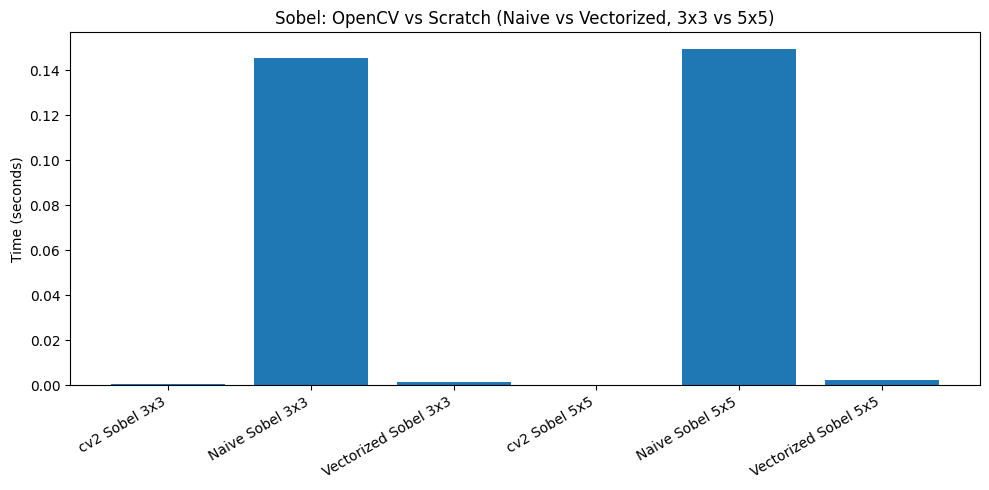

In [10]:
plt.figure(figsize=(10,5))
x = np.arange(len(labels))
plt.bar(x, times)
plt.xticks(x, labels, rotation=30, ha="right")
plt.ylabel("Time (seconds)")
plt.title("Sobel: OpenCV vs Scratch (Naive vs Vectorized, 3x3 vs 5x5)")
plt.tight_layout()
plt.show()
